# IDORT literature tests: beams, shadow, emitting cylinder, radiative shocks

The literature tests of the IDORT paper (Ma et al. 2025) and Jiang (2021, ApJS 253, 49) with
the production keys (`decks/idort_*.athinput`), each against an exact or semi-analytic solution:

- **crossing beams** in vacuum (`idort_beams`): two beams enter at $x_1 = -2$ at $\pm 45$ deg;
  exact: the straight beams. Also on 4 MeshBlocks (`idort_beams_mb`, no plot: identical in
  tile mode along $x_2$, $7\times10^{-11}$ in block mode along $x_1$, bound $10^{-8}$).
- **shadow** (`idort_shadow`, ring of 12 rays; `idort_shadow_gl`, the general $8\times32$ set):
  two beams at $\pm15$ deg past an opaque ellipse; exact: the beams attenuated along straight rays.
- **emitting cylinder** (`idort_cylinder`): $r<1$, $\rho\kappa = 10$, $aT^4 = 1$ in vacuum;
  exact: the transport solution along $y = 0$ (`ref/idort_cylinder_exact.npz`).
- **radiative shocks** (`idort_radshock_m2`, `idort_radshock_m5`): Lowrie & Edwards (2008) at
  Mach 2 and 5, started from the semi-analytic profile (`ref/idort_radshock_m*.txt`), which the
  scheme must keep.
- **hot gas cooling into radiation** at large steps (`idort_thermal_eq2`): $T(t)$ against the exact ODE.

Criteria: L1 within 5 % of the reference values (see `ref/references.json`). Code units
except the shocks (cgs).

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath('.'))   # this notebook's folder: tests/vet_clean/notebooks
import nbutil as nb                        # nb.suite, nb.verdict, nb.vett (readers), nb.rt (run_tests)

# the athena binary (a CPU build, default the one tests/vet_clean/run_tests.sh builds)
EXE = os.path.abspath(os.environ.get('ATHENA_EXE', '../../../build_vettest/src/athena'))
# where the runs go; a test whose run is already there is only loaded, not rerun
WORK = os.path.abspath(os.environ.get('VET_NB_WORKDIR', 'runs'))
THREADS = int(os.environ.get('VET_NB_THREADS', '4'))   # OpenMP threads per run
nb.style()
print('binary', os.path.relpath(EXE), '\nruns  ', os.path.relpath(WORK))

binary ../../../build_vettest/src/athena 
runs   runs


In [2]:
TESTS = ['idort_beams', 'idort_beams_mb', 'idort_shadow', 'idort_shadow_gl', 'idort_cylinder',
         'idort_radshock_m2', 'idort_radshock_m5', 'idort_thermal_eq2']
res = {t: nb.suite(t, EXE, WORK, THREADS) for t in TESTS}
vett, rt = nb.vett, nb.rt

loading the existing run runs/idort_beams
loading the existing run runs/idort_beams_mb
loading the existing run runs/idort_shadow
loading the existing run runs/idort_shadow_gl
loading the existing run runs/idort_cylinder
loading the existing run runs/idort_radshock_m2
loading the existing run runs/idort_radshock_m5
loading the existing run runs/idort_thermal_eq2


## Crossing beams

Left: E of the run; middle: the exact straight beams (cell averages); right: cuts across the
beams at four heights $x_1$ (lines: code, dashed: exact). The beams, 4 cells wide, stay straight
and go on after crossing; they carry 1.19 times the exact energy (`lum_top`), which
dominates L1; the energy flux through every row equals the injected flux to 6e-8 (`flux_err`).

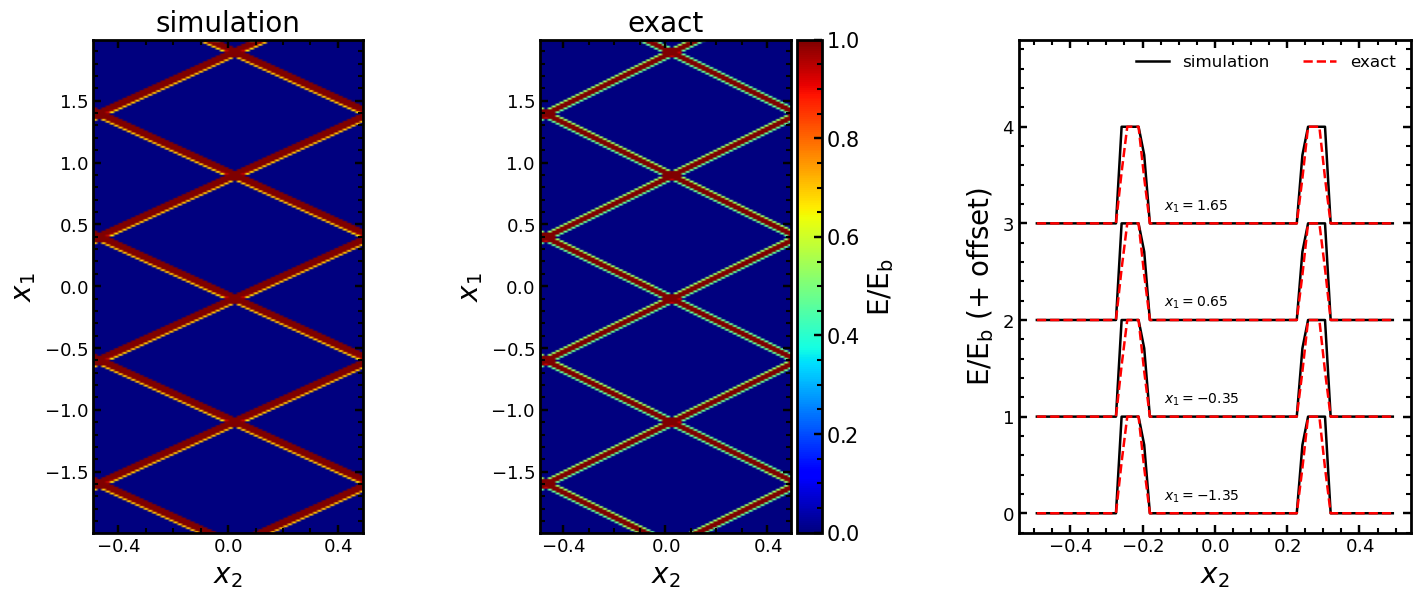

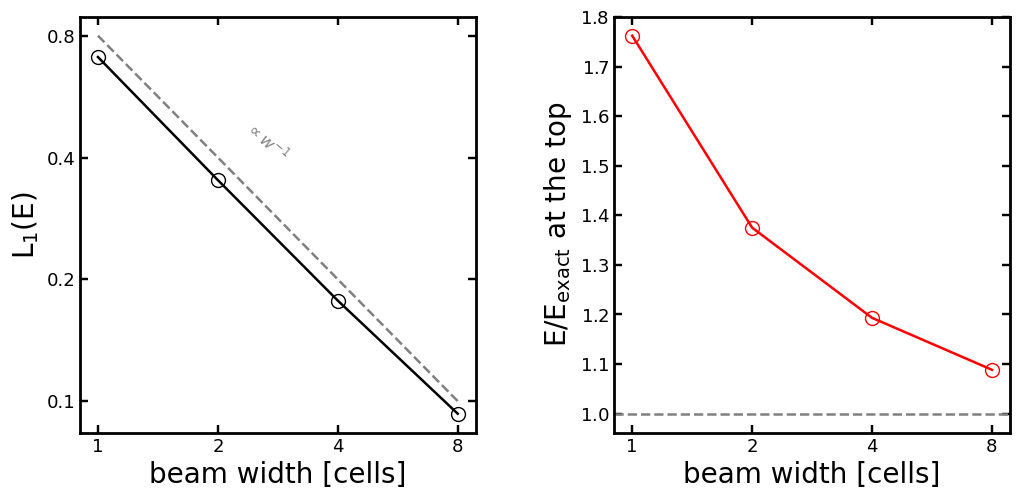

PASS idort_beams   criterion {"max": {"flux_err": 1e-05}, "near": {"L1": [0.1772, 0.05], "lum_top": [1.1932, 0.05]}}
PASS idort_beams_mb   criterion {"equal": {"maxdiff_tile_x2": 0.0}, "max": {"maxdiff_block_x1": 1e-08}}


In [3]:
LB, TK, LG = 20, 15, 12
def bar(fig, im, ax, lab):
    c = fig.colorbar(im, ax=ax, pad=0.02); c.set_label(lab, fontsize=LB); c.ax.tick_params(labelsize=TK)
# ---- beams
d = os.path.join(WORK, 'idort_beams', 'run'); E, Ex = vett.last_bin(d, 'vet')['vet_e'][0], rt.beams_exact(d); x1, x2, _ = vett.cell_centres(d)
fig, ax = plt.subplots(1, 3, figsize=(17, 6.4), gridspec_kw={'width_ratios': [1, 1.12, 1.45], 'wspace': 0.55})
ext = [x2[0], x2[-1], x1[0], x1[-1]]
for a, f, t in ((ax[0], E, 'simulation'), (ax[1], Ex, 'exact')):
    im = a.imshow(f.T, origin='lower', extent=ext, aspect='auto', vmin=0, vmax=1, cmap='jet')
    a.set_xlabel(r'$x_2$', fontsize=LB); a.set_ylabel(r'$x_1$', fontsize=LB); a.set_title(t, fontsize=LB); a.set_xticks([-0.4, 0, 0.4])
bar(fig, im, ax[1], r'$\rm E / E_b$')
for k, r in enumerate((-1.35, -0.35, 0.65, 1.65)):
    i = int(np.argmin(np.abs(x1 - r)))
    ax[2].plot(x2, E[:, i] + k, 'k-', label=r'simulation' if k == 0 else None); ax[2].plot(x2, Ex[:, i] + k, 'r--', label=r'exact' if k == 0 else None)
    ax[2].text(-0.14, k + 0.14, r'$x_1 = %.2f$' % x1[i], fontsize=LG - 2)
ax[2].set_xlabel(r'$x_2$', fontsize=LB); ax[2].set_ylabel(r'$\rm E / E_b$ (+ offset)', fontsize=LB); ax[2].set_ylim(-0.2, 4.9); ax[2].legend(fontsize=LG, loc='upper right', ncol=2)
plt.show()
# the width ladder: the same beams 1, 2, 4 and 8 cells wide (4 short runs; not a suite test)
L = {}
for w in (1, 2, 4, 8):
    d = os.path.join(WORK, 'idort_beams_w%d' % w)
    if not os.path.exists(os.path.join(d, 'run.log')):
        os.makedirs(d, exist_ok=True)
        vett.make_deck(os.path.join(nb.SUITE, 'decks', 'idort_beams.athinput'), os.path.join(d, 'in.athinput'),
                       {'rad_vet/implicit_beam0_y1': -0.109375 + w/64., 'rad_vet/implicit_beam1_y1': 0.09375 + w/64.})
        rc, wall, log = vett.run([EXE], d, ['-i', 'in.athinput'], threads=THREADS)
        assert rc == 0, log[-400:]
    Ew, Exw = vett.last_bin(d, 'vet')['vet_e'][0], rt.beams_exact(d)
    L[w] = dict(L1=rt.l1(Ew, Exw), lum_top=float(Ew[:, -3].sum()/Exw[:, -3].sum()))
w = np.array(sorted(L))
fig, ax = plt.subplots(1, 2, figsize=(12, 5.4), gridspec_kw={'wspace': 0.35})
ax[0].loglog(w, [L[k]['L1'] for k in w], 'ko-', mfc='none', ms=10); ax[0].loglog(w, 0.8/w, '--', c='0.5'); ax[0].text(2.3, 0.39, r'$\propto w^{-1}$', color='0.5', rotation=-41, fontsize=LG)
ax[1].semilogx(w, [L[k]['lum_top'] for k in w], 'ro-', mfc='none', ms=10); ax[1].axhline(1.0, c='0.5', ls='--')
for a, y in zip(ax, (r'$\rm L_1(E)$', r'$\rm E / E_{exact}$ at the top')):
    a.set_xlabel(r'beam width [cells]', fontsize=LB); a.set_ylabel(y, fontsize=LB); a.set_xticks(w); a.set_xticklabels([str(k) for k in w]); a.minorticks_off()
ax[0].set_yticks([0.1, 0.2, 0.4, 0.8]); ax[0].set_yticklabels(['0.1', '0.2', '0.4', '0.8'])
plt.show()
for t in ('idort_beams', 'idort_beams_mb'):
    nb.verdict(t, res[t])


## Shadow

Left: E of the ring run, log scale. Right: cuts along $x_2$ behind the ellipse (at
$x_1 = 0.25$ and $0.4$) for both ray sets with the exact attenuated beams (the general set
snaps the beams to its nearest rays, 11.4 deg; its exact field uses that angle).

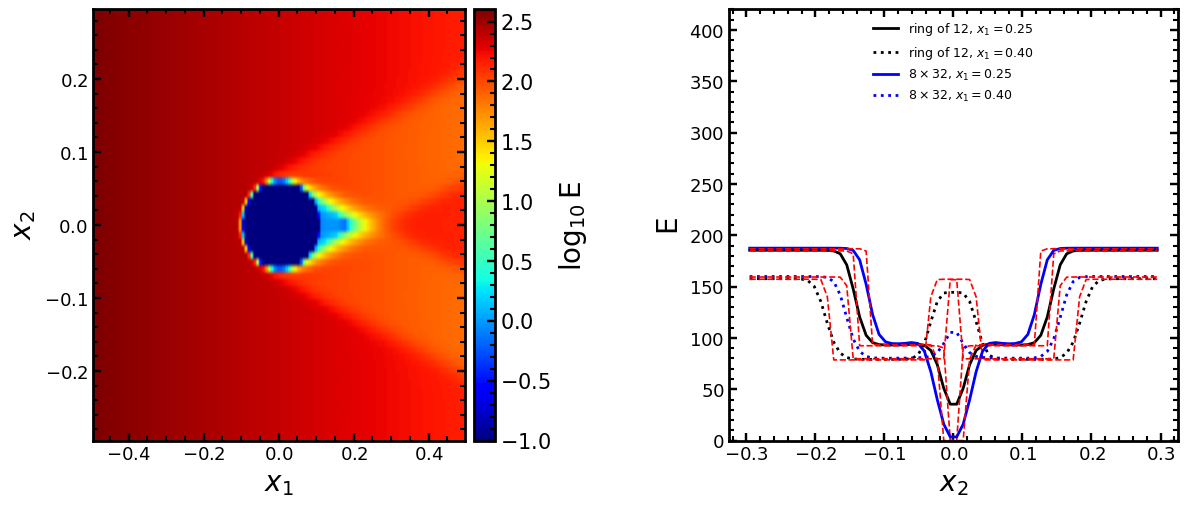

PASS idort_shadow   criterion {"near": {"L1": [0.0138, 0.05]}}
PASS idort_shadow_gl   criterion {"near": {"L1": [0.0126, 0.05]}}


In [4]:
# ---- shadow
fig, ax = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw={'wspace': 0.42})
for t, c in (('idort_shadow', 'k'), ('idort_shadow_gl', 'b')):
    d = os.path.join(WORK, t, 'run'); E, Ex = vett.last_bin(d, 'vet')['vet_e'][0], rt.shadow_exact(d); x1, x2, _ = vett.cell_centres(d)
    if t == 'idort_shadow':
        im = ax[0].imshow(np.log10(np.maximum(E, 1e-3)), origin='lower', aspect='auto', extent=[x1[0], x1[-1], x2[0], x2[-1]], vmin=-1, vmax=np.log10(400), cmap='jet')
        bar(fig, im, ax[0], r'$\rm \log_{10} E$'); ax[0].set_xlabel(r'$x_1$', fontsize=LB); ax[0].set_ylabel(r'$x_2$', fontsize=LB)
    for xc, ls in ((0.25, '-'), (0.4, ':')):
        i = int(np.argmin(np.abs(x1 - xc))); ax[1].plot(x2, E[:, i], ls, c=c, lw=2, label=r'%s, $x_1 = %.2f$' % ('ring of 12' if c == 'k' else r'$8 \times 32$', x1[i])); ax[1].plot(x2, Ex[:, i], '--', c='r', lw=1.2)
ax[1].set_xlabel(r'$x_2$', fontsize=LB); ax[1].set_ylabel(r'$\rm E$', fontsize=LB); ax[1].set_ylim(0, 420); ax[1].legend(fontsize=LG - 3, loc='upper center', ncol=1)
plt.show()
for t in ('idort_shadow', 'idort_shadow_gl'):
    nb.verdict(t, res[t])


## Emitting cylinder

E, the energy flux $\Phi_x/c$ (`vet_phi1`) and the face momentum $F_x/c$ (`vet_f1`) along
$y = 0$ against the exact transport solution. Outside the cylinder E agrees to 1.1 % and the
energy flux to 1.2 % (`F_out`); the face momentum is about 20 % above the exact flux
(`FH_out`, a regression reference).

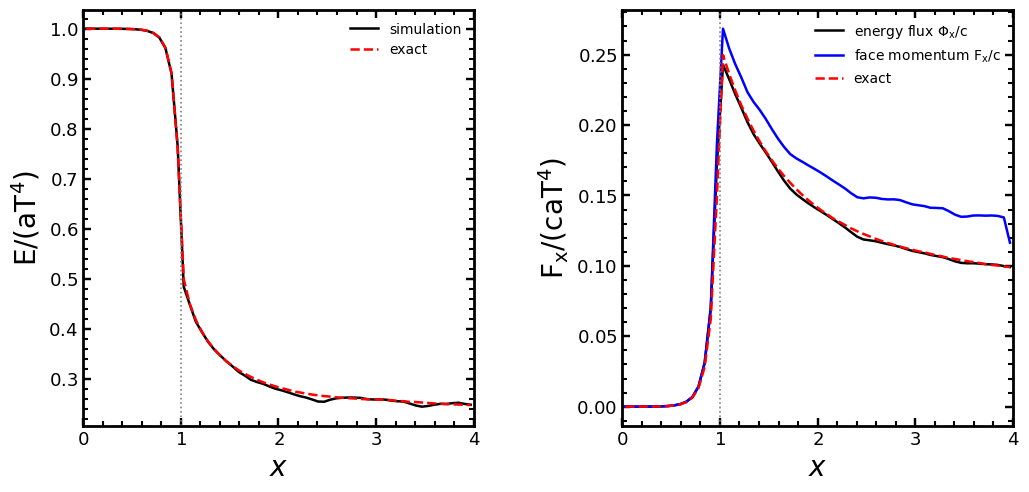

PASS idort_cylinder   criterion {"near": {"E_in": [0.000531, 0.05], "E_out": [0.0111, 0.05], "F_out": [0.0116, 0.05], "FH_out": [0.203, 0.05]}}


True

In [5]:
# ---- cylinder
d = os.path.join(WORK, 'idort_cylinder', 'run'); m, (x1, x2, _) = vett.last_bin(d, 'vet'), vett.cell_centres(d); ex = np.load(os.path.join(nb.SUITE, 'ref', 'idort_cylinder_exact.npz')); cl = float(vett.parse_deck_text(open(os.path.join(d, 'in.athinput')).read())['rad_vet']['c_light'])
j, s = np.argsort(np.abs(x2))[:2], x1 > 0
fig, ax = plt.subplots(1, 2, figsize=(12, 5.4), gridspec_kw={'wspace': 0.38})
ax[0].plot(x1[s], m['vet_e'][0][j].mean(axis=0)[s], 'k-', label='simulation'); ax[0].plot(ex['x'], ex['E'], 'r--', label='exact')
ax[1].plot(x1[s], m['vet_phi1'][0][j].mean(axis=0)[s]/cl, 'k-', label=r'energy flux $\rm \Phi_x / c$'); ax[1].plot(x1[s], m['vet_f1'][0][j].mean(axis=0)[s]/cl, 'b-', label=r'face momentum $\rm F_x / c$'); ax[1].plot(ex['x'], ex['F'], 'r--', label='exact')
for a, y in zip(ax, (r'$\rm E / (a T^4)$', r'$\rm F_x / (c a T^4)$')):
    a.axvline(1.0, c='0.5', ls=':', lw=1.2); a.set_xlabel(r'$x$', fontsize=LB); a.set_ylabel(y, fontsize=LB); a.set_xlim(0, 4); a.legend(fontsize=LG - 2, loc='upper right')
plt.show()
nb.verdict('idort_cylinder', res['idort_cylinder'])


## Radiative shocks (Lowrie & Edwards 2008)

Density (top) and gas and radiation temperatures (bottom) at $t = 2\times10^{-10}$ s against
the semi-analytic profiles, Mach 2 (left) and Mach 5 (right), 256 cells; $x_s$ is the shock
position of the reference. No shift is applied.

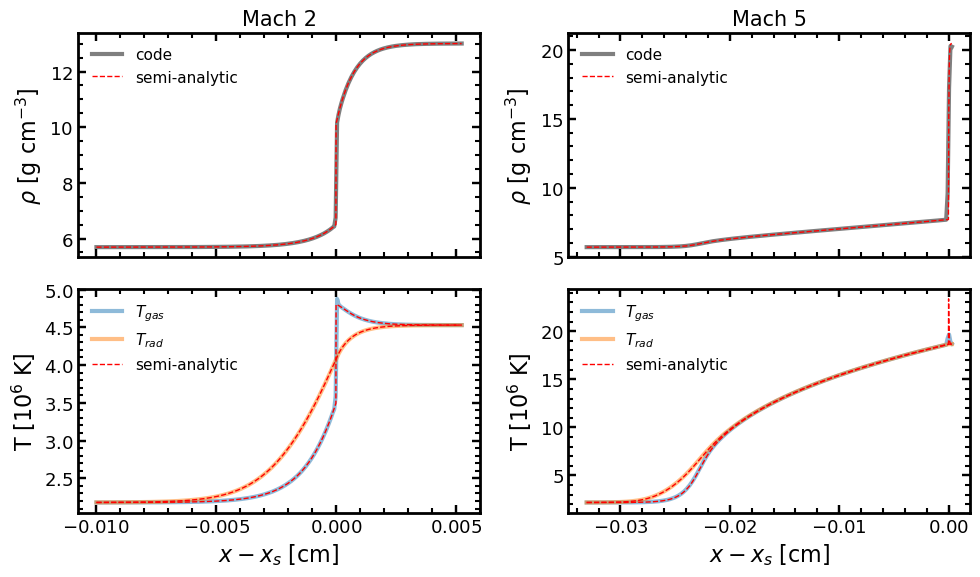

PASS idort_radshock_m2   criterion {"near": {"L1_rho": [0.000356, 0.05], "L1_v": [0.000213, 0.05], "L1_Tg": [0.000385, 0.05], "L1_Tr": [0.00026, 0.05]}}
PASS idort_radshock_m5   criterion {"near": {"L1_rho": [0.00171, 0.05], "L1_v": [0.000822, 0.05], "L1_Tg": [0.00161, 0.05], "L1_Tr": [0.000938, 0.05]}}


In [6]:
fig, axs = plt.subplots(2, 2, figsize=(10, 6), sharex='col')
for col, m in enumerate(('2', '5')):
    t = 'idort_radshock_m' + m
    d = os.path.join(WORK, t, 'run')
    p = vett.parse_deck_text(open(os.path.join(d, 'in.athinput')).read())
    tu, ar = float(p['problem']['vet_shock_tunit']), float(p['rad_vet']['arad'])
    h, r = vett.last_bin(d, 'hydro_w'), vett.last_bin(d, 'vet')
    x = vett.cell_centres(d)[0] - float(p['problem']['vet_shock_xs'])
    rho = h['dens'].mean(axis=(0, 1))
    tg = (2.0/3.0)*h['eint'].mean(axis=(0, 1))/rho/tu
    tr = (np.maximum(r['vet_e'].mean(axis=(0, 1)), 0.0)/ar)**0.25/tu
    a = np.loadtxt(os.path.join(nb.SUITE, 'ref', t + '.txt'))
    a = a[(a[:, 0] >= x[0]) & (a[:, 0] <= x[-1])]
    axs[0, col].plot(x, rho, 'k-', lw=3, alpha=0.5, label='code')
    axs[0, col].plot(a[:, 0], a[:, 1], 'r--', lw=1, label='semi-analytic')
    axs[1, col].plot(x, tg/1e6, 'C0-', lw=3, alpha=0.5, label='$T_{gas}$')
    axs[1, col].plot(x, tr/1e6, 'C1-', lw=3, alpha=0.5, label='$T_{rad}$')
    axs[1, col].plot(a[:, 0], a[:, 3]/1e6, 'r--', lw=1, label='semi-analytic')
    axs[1, col].plot(a[:, 0], a[:, 4]/1e6, 'r--', lw=1)
    axs[0, col].set(title='Mach ' + m, ylabel=r'$\rho$ [g cm$^{-3}$]')
    axs[1, col].set(xlabel='$x - x_s$ [cm]', ylabel='T [$10^6$ K]')
    axs[0, col].legend(fontsize=11); axs[1, col].legend(fontsize=11)
for a in axs.flat: a.locator_params(axis='x', nbins=4)
plt.tight_layout(); plt.show()
for t in ('idort_radshock_m2', 'idort_radshock_m5'):
    nb.verdict(t, res[t])

## Hot gas cooling into radiation at large time steps

Uniform gas ($T_0 = 100$) and radiation ($E_0 = 1$), $\kappa = 1$, $c = 100$, $\Delta t =
5\times10^{-4}$: each step is 5 to $10^5$ relaxation times. Left: $T(t)$ with the exact
equilibrium; right: $|T/T_{exact} - 1|$ (the first dump, after 5 steps, dominates).

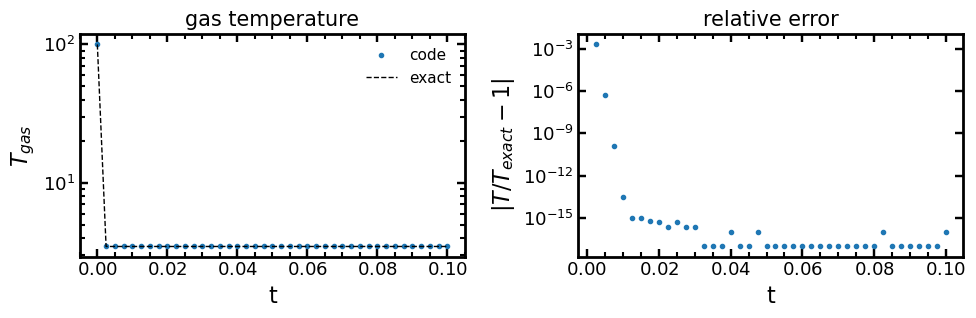

PASS idort_thermal_eq2   criterion {"near": {"errT": [0.00196, 0.05]}, "max": {"dEtot": 1e-13}}


True

In [7]:
d = os.path.join(WORK, 'idort_thermal_eq2', 'run')
p = vett.parse_deck_text(open(os.path.join(d, 'in.athinput')).read())
rho, gm1 = float(p['problem']['gas_rho']), float(p['hydro']['gamma']) - 1.0
T0, E0 = float(p['problem']['gas_eint'])*gm1/rho, float(p['problem']['e_rad'])
rate = float(p['rad_vet']['c_light'])*float(p['rad_vet']['kappa_p'])*rho
ts, T, Tx = [], [], []
for f in vett.bins(d, 'hydro_w'):
    h = vett.read_bin(f)
    ts.append(h['time']); T.append((h['eint']*gm1/h['dens']).mean())
    Tx.append(vett.relax_ode(T0, rho*T0/gm1 + E0, rho, gm1, rate, h['time']) if h['time'] > 0 else T0)
ts, T, Tx = np.array(ts), np.array(T), np.array(Tx)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
axs[0].semilogy(ts, T, 'o', ms=3, label='code'); axs[0].semilogy(ts, Tx, 'k--', lw=1, label='exact')
axs[0].set(xlabel='t', ylabel='$T_{gas}$', title='gas temperature'); axs[0].legend(fontsize=11)
axs[1].semilogy(ts[1:], np.maximum(np.abs(T[1:]/Tx[1:] - 1.0), 1e-17), 'o', ms=3)
axs[1].set(xlabel='t', ylabel='$|T/T_{exact} - 1|$', title='relative error')
plt.tight_layout(); plt.show()
nb.verdict('idort_thermal_eq2', res['idort_thermal_eq2'])